#Project 11: Handwritten Digit Classification Using CNN

1. First, let’s load the libraries and dataset

We’ll use the MNIST dataset, which contains pictures of handwritten digits from 0 to 9.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Number of classes:", len(np.unique(y_train)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Number of classes: 10


2. Get the images ready

The pixel values range from 0 to 255, so we’ll scale them to a range between 0 and 1. We’ll also add a channel dimension so the images are ready for the CNN.

In [ ]:
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# dimension: (28, 28) -> (28, 28, 1)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Processed training shape:", X_train.shape)
print("Processed testing shape:", X_test.shape)

Processed training shape: (60000, 28, 28, 1)
Processed testing shape: (10000, 28, 28, 1)


3. Let’s look at a few images

Here are the first 10 images from the training dataset, along with their correct digit labels.


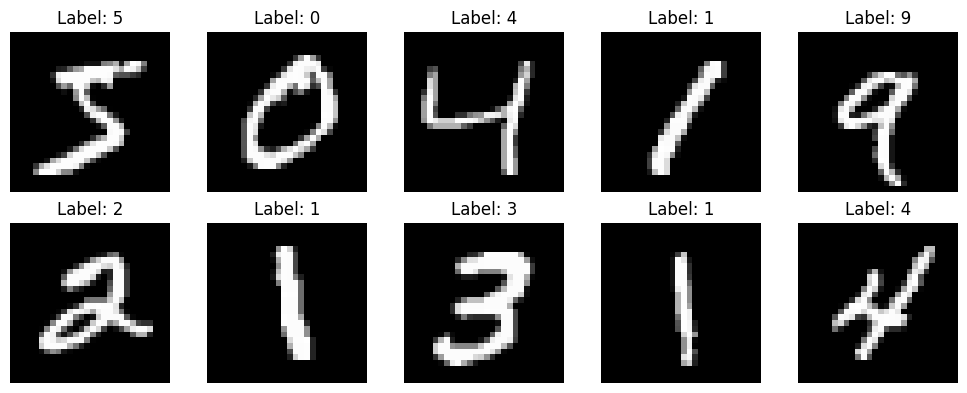

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

4. Let’s build the CNN model

The model uses convolution and pooling layers to find useful features in the images. The final layers use those features to predict which digit is shown.

In [ ]:

model = Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

5. Let’s train the model

We’ll train the CNN for 10 epochs and use a small part of the training data to check how well it is learning.

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9177 - loss: 0.2739 - val_accuracy: 0.9822 - val_loss: 0.0606
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9761 - loss: 0.0793 - val_accuracy: 0.9870 - val_loss: 0.0450
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9826 - loss: 0.0565 - val_accuracy: 0.9878 - val_loss: 0.0391
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9859 - loss: 0.0455 - val_accuracy: 0.9898 - val_loss: 0.0367
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9889 - loss: 0.0352 - val_accuracy: 0.9915 - val_loss: 0.0320
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9901 - loss: 0.0317 - val_accuracy: 0.9902 - val_loss: 0.0320
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9911 - loss: 0.0273 - val_accuracy: 0.9908 - val_loss: 0.0334
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9921 - loss: 0.0243 - val_accuracy: 

6. Let’s check the accuracy and loss

These graphs show how the model’s accuracy and loss change during training for both the training data and validation data.

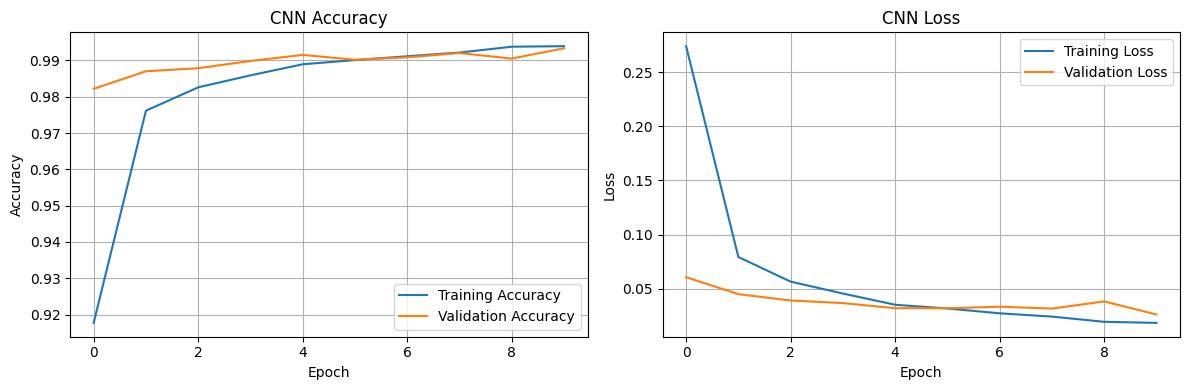

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

7. Let’s see how well the model performs

Now we’ll test the trained model on images it hasn’t used for training and check its accuracy and loss.

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0239
Test Accuracy: 99.20%


8. Let’s check the confusion matrix

The confusion matrix compares the actual digits with the digits predicted by the model. Values outside the main diagonal show where the model made mistakes.

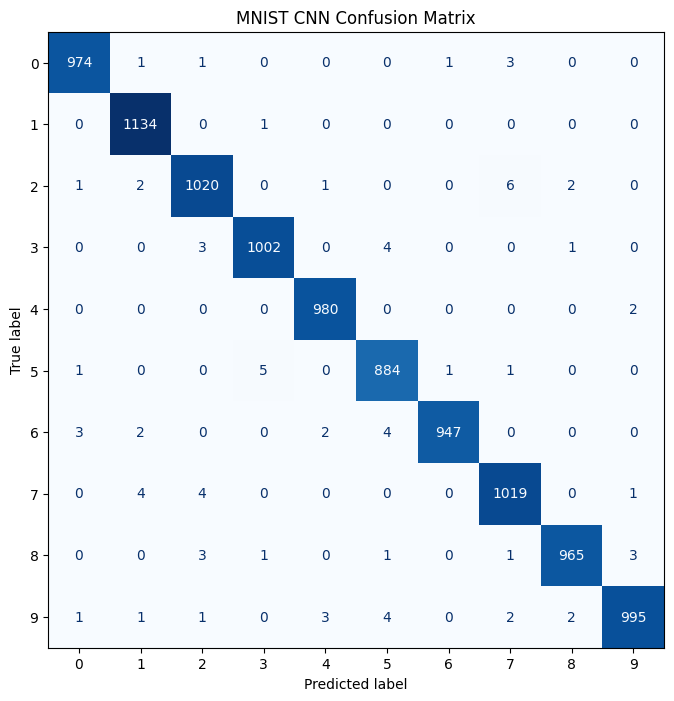

In [ ]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap="Blues", ax=ax, values_format="d", colorbar=False)
plt.title("MNIST CNN Confusion Matrix")
plt.show()

9. Let’s look at the classification report

This report shows precision, recall and F1-score for each digit from 0 to 9. These values help us understand how well the model predicts each digit.

In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(10),
        target_names=[str(i) for i in range(10)],
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9939    0.9939    0.9939       980
           1     0.9913    0.9991    0.9952      1135
           2     0.9884    0.9884    0.9884      1032
           3     0.9931    0.9921    0.9926      1010
           4     0.9939    0.9980    0.9959       982
           5     0.9855    0.9910    0.9883       892
           6     0.9979    0.9885    0.9932       958
           7     0.9874    0.9912    0.9893      1028
           8     0.9948    0.9908    0.9928       974
           9     0.9940    0.9861    0.9900      1009

    accuracy                         0.9920     10000
   macro avg     0.9920    0.9919    0.9920     10000
weighted avg     0.9920    0.9920    0.9920     10000



10. Let’s try some predictions

Here, we’ll compare the model’s predictions with the actual labels for 15 test images. Green titles mean the prediction is correct, while red titles mean it is incorrect.

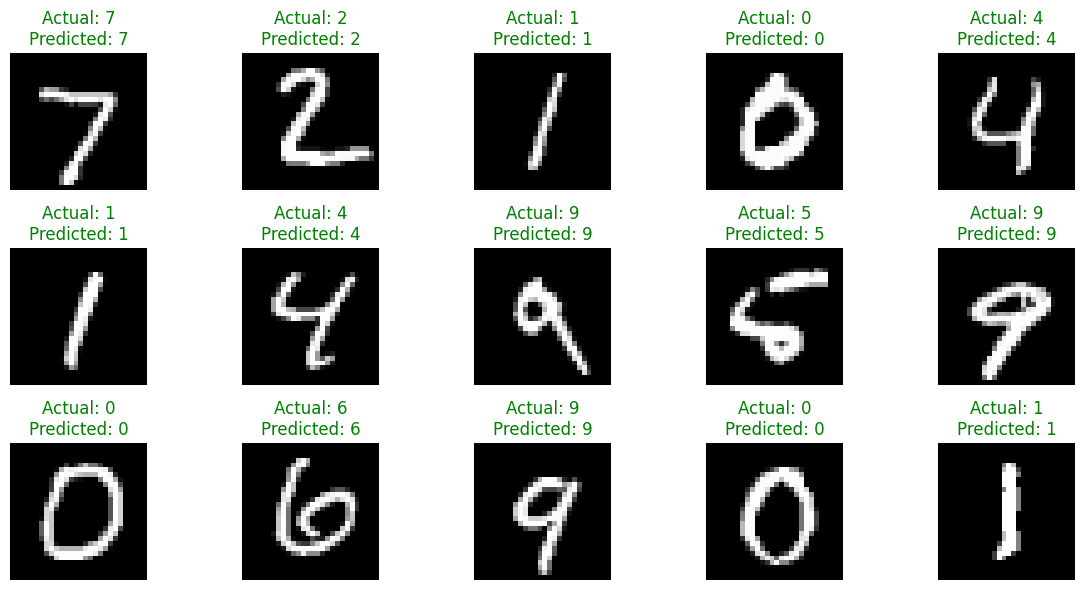

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i].squeeze(), cmap="gray")

    actual = y_test[i]
    predicted = y_pred[i]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In this project, we used a CNN to recognize handwritten digits from the MNIST dataset. We loaded and prepared the images, built the model, and trained it using the training data.

We then checked its performance using test accuracy, a confusion matrix, a classification report and sample predictions. These results help us understand how accurately the model recognizes digits and where it sometimes makes mistakes.

Result: The CNN was trained to classify handwritten digits from 0 to 9. The final test accuracy will be displayed when you run the notebook.